# HDT 8: Redes Neuronales

**Ciencia de Datos, Sección A** · Asignada: jueves 15 de octubre · **Entrega: martes 27 de octubre, 23:59**

**Nombre:** George Albadr

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

La entrega es el martes del repaso (el 20 es feriado): no la dejen para el final, el Parcial II es el jueves 29.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

def frontera(modelo, X, y, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150),
                         np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150))
    Z = modelo.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[AZUL, ROJO], alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, ROJO, AZUL), s=12)
    ax.set_title(titulo, fontsize=10)

## Los datos

Dos problemas donde la forma importa:

**La alarma** (parte A): un sensor dispara la alarma cuando **exactamente una** de dos señales está encendida (la diagonal de la sesión 22, con otros 240 puntos). **Los anillos** (parte B): un punto adentro de un anillo, como el ejercicio 2 de clase, con otros números.

In [ ]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(15)
esquinas = rng.integers(0, 2, size=(240, 2))
X_alarma = esquinas + rng.normal(0, 0.15, (240, 2))
y_alarma = (esquinas[:, 0] != esquinas[:, 1]).astype(int)

X_ani, y_ani = make_circles(n_samples=500, noise=0.12, factor=0.45, random_state=8)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_ani, y_ani, test_size=0.3, random_state=42)

print("alarma:", len(X_alarma), "puntos | anillos:", len(X_ani), "puntos")

alarma: 240 puntos | anillos: 500 puntos


## Parte A · La recta falla, la red a mano no (0.7 pt)

### Ejercicio 1 (0.20): la recta contra la diagonal

Entrenar una `LogisticRegression` sobre la alarma y reportar sus aciertos. Graficar los puntos (ROJO = alarma, AZUL = no) con `eje_limpio`. En un comentario: ¿por qué este número y no algo mejor?

aciertos_recta: 0.54


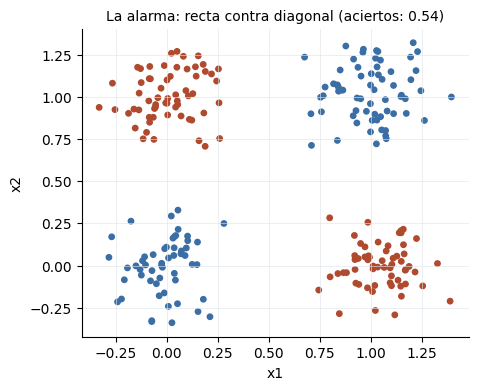

In [ ]:
from sklearn.linear_model import LogisticRegression

recta = LogisticRegression(random_state=0).fit(X_alarma, y_alarma)  # entrenar sobre X_alarma, y_alarma
aciertos_recta = recta.score(X_alarma, y_alarma)
print(f"aciertos_recta: {aciertos_recta:.2f}")

# graficar los puntos
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_alarma[:, 0], X_alarma[:, 1], c=np.where(y_alarma == 1, ROJO, AZUL), s=15)
ax.set_title(f"La alarma: recta contra diagonal (aciertos: {aciertos_recta:.2f})", fontsize=10)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
eje_limpio(ax)
plt.show()

# Respuesta: la alarma es un XOR: suena en (0,1) y (1,0) y no suena en (0,0) ni (1,1).
# Las dos clases quedan en diagonales cruzadas, y una sola recta no puede dejar las dos esquinas
# rojas de un lado y las dos azules del otro. Lo más que logra una recta es aislar una esquina (~75%),
# pero la logística ni siquiera llega ahí: al minimizar el log-loss los puntos se compensan entre sí
# y la recta queda casi plana (coeficientes -0.05 y -0.18), con probabilidades cerca de 0.5 en todo el plano.
# De ahí sale el 0.54: con clases 50/50, es casi lo mismo que tirar una moneda.

# Verificación (descomentar):
assert round(aciertos_recta, 2) == 0.54


### Ejercicio 2 (0.30): la red a mano, verificada

Completar `red_a_mano` con la receta de clase: neurona 1 con pesos $(2, 2)$ y sesgo $-1$; neurona 2 con pesos $(2, 2)$ y sesgo $-3$; ambas con ReLU; salida $= h_1 - 3 h_2$. Armar la tabla de las cuatro esquinas e imprimirla.

In [ ]:
def relu(z):
    return np.maximum(0, z)

def red_a_mano(x1, x2):
    # las dos sumas con pesos, las dos ReLU y la salida
    z1 = 2 * x1 + 2 * x2 - 1
    h1 = relu(z1)
    z2 = 2 * x1 + 2 * x2 - 3
    h2 = relu(z2)
    salida = h1 - 3 * h2
    return salida

filas = []
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    # llenar la tabla: x1, x2, h1, h2, salida
    z1 = 2 * x1 + 2 * x2 - 1
    h1 = relu(z1)
    z2 = 2 * x1 + 2 * x2 - 3
    h2 = relu(z2)
    salida = red_a_mano(x1, x2)
    filas.append({"x1": x1, "x2": x2, "h1": h1, "h2": h2, "salida": salida})

tabla_esquinas = pd.DataFrame(filas)
print(tabla_esquinas)

# Verificación (descomentar):
assert red_a_mano(0, 1) == 1 and red_a_mano(1, 0) == 1
assert red_a_mano(0, 0) == 0 and red_a_mano(1, 1) == 0


   x1  x2  h1  h2  salida
0   0   0   0   0       0
1   0   1   1   0       1
2   1   0   1   0       1
3   1   1   3   1       0


### Ejercicio 3 (0.20): la misma red sobre los 240 puntos

Aplicar `red_a_mano` a todos los puntos de la alarma (decidir sí cuando la salida pasa de 0.5) y reportar los aciertos. Comparar contra la recta del ejercicio 1 en un comentario.

In [ ]:
salidas = red_a_mano(X_alarma[:, 0], X_alarma[:, 1])  # la red sobre cada punto de X_alarma
pred_mano = (salidas > 0.5).astype(int)
aciertos_mano = np.mean(pred_mano == y_alarma)
print(f"aciertos_mano: {aciertos_mano:.2f}")

# Respuesta: 0.89 contra el 0.54 de la recta. Cada neurona ReLU mete un quiebre: h1 se prende cuando
# x1 + x2 pasa de 0.5 y h2 cuando pasa de 1.5. Con salida = h1 - 3*h2 queda una franja diagonal,
# 0.75 < x1 + x2 < 1.875, donde la red dice "alarma". Ahí caen (0,1) y (1,0), y (0,0) y (1,1) quedan afuera.
# El 11% que falla viene del ruido: hay puntos que se corren lo suficiente para cruzar el borde de la franja,
# y como los pesos los pusimos a mano (no se entrenaron), la red no se ajusta a eso.

# Verificación (descomentar):
assert round(aciertos_mano, 2) == 0.89


aciertos_mano: 0.89


## Parte B · La red que aprende (0.7 pt)

Los anillos: un círculo adentro de otro. La pregunta de la clase: ¿cuántos quiebres pide esta frontera?

### Ejercicio 4 (0.25): ¿cuántas neuronas pide un anillo?

Para [1, 2, 4, 8, 16, 64] neuronas de en medio: entrenar `MLPClassifier` (`activation="relu"`, `max_iter=3000`, `random_state=0`) sobre el train de los anillos y guardar train y test en una tabla. ¿Dónde deja de mejorar?

In [ ]:
from sklearn.neural_network import MLPClassifier
import warnings
warnings.filterwarnings("ignore")

filas = []
for h in [1, 2, 4, 8, 16, 64]:
    # entrenar y guardar neuronas, train, test (redondeados a 2)
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu", max_iter=3000, random_state=0)
    mlp.fit(Xa_train, ya_train)
    tr = round(mlp.score(Xa_train, ya_train), 2)
    te = round(mlp.score(Xa_test, ya_test), 2)
    filas.append({"neuronas": h, "train": tr, "test": te})

tabla_h = pd.DataFrame(filas)
print(tabla_h)

# Con 1 y 2 neuronas no alcanza (test 0.45 y 0.58). Con 4 sube a 0.95 y con 8 llega a 0.99.
# De ahí en adelante ya no mejora: 16 y 64 dan el mismo 0.99 en test. Deja de mejorar en 8.

# Verificación (descomentar):
assert tabla_h["test"].tolist() == [0.45, 0.58, 0.95, 0.99, 0.99, 0.99]


   neuronas  train  test
0         1   0.52  0.45
1         2   0.58  0.58
2         4   0.98  0.95
3         8   1.00  0.99
4        16   0.99  0.99
5        64   0.99  0.99


### Ejercicio 5 (0.25): las fronteras, dibujadas

Tres paneles con `frontera(...)`: redes de 1, 4 y 8 neuronas sobre el test de los anillos, con los aciertos de test en cada título.

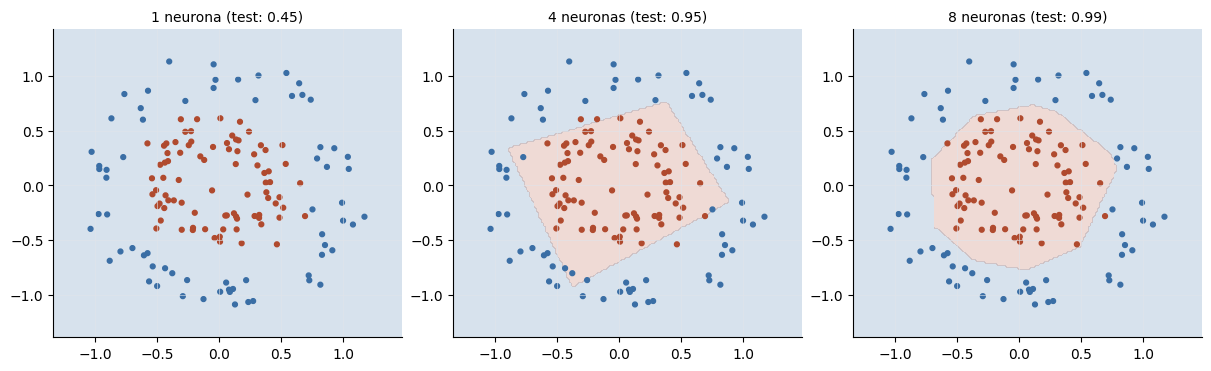

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
# entrenar cada tamaño y llamar a frontera con su título
for h, ax in zip([1, 4, 8], axes):
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu", max_iter=3000, random_state=0)
    mlp.fit(Xa_train, ya_train)
    te = mlp.score(Xa_test, ya_test)
    frontera(mlp, Xa_test, ya_test, ax, f"{h} neurona{'s' if h > 1 else ''} (test: {te:.2f})")
    eje_limpio(ax)

plt.show()

# Verificación (descomentar):
assert len(axes) == 3


### Ejercicio 6 (0.20): el tamaño del paso, otra vez

Entrenar la red de 8 neuronas con `solver="sgd"` y `learning_rate_init` en [0.001, 0.1, 8.0] (`max_iter=400`), graficando la curva de error (`loss_curve_`) de cada una. Guardar los aciertos de test en `tests_paso`. En un comentario: ¿qué historia cuenta cada curva?

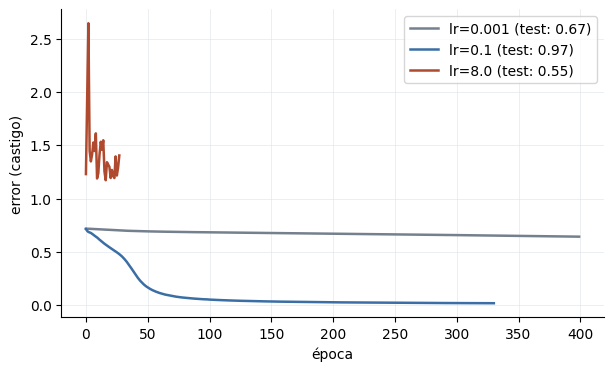

In [ ]:
tests_paso = {}
fig, ax = plt.subplots(figsize=(7, 4))
# las tres corridas, cada loss_curve_ al plot, y tests_paso[lr] = ...
for lr, color in zip([0.001, 0.1, 8.0], [GRIS, AZUL, ROJO]):
    mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="sgd", learning_rate_init=lr, max_iter=400, random_state=0)
    mlp.fit(Xa_train, ya_train)
    score_te = mlp.score(Xa_test, ya_test)
    tests_paso[lr] = score_te
    ax.plot(mlp.loss_curve_, label=f"lr={lr} (test: {score_te:.2f})", color=color, lw=1.8)

ax.set_xlabel("época"); ax.set_ylabel("error (castigo)")
ax.legend(); eje_limpio(ax)
plt.show()

# Respuesta:
# - lr=0.001: el paso es tan chico que en 400 épocas el error apenas baja (de 0.72 a 0.64). Se acaban
#   las épocas antes de que la red aprenda y el test queda en 0.67.
# - lr=0.1: la curva baja pareja hasta casi cero (0.02). Para sola en la época 331, cuando el error ya
#   no mejora, y el test es 0.97.
# - lr=8.0: el paso es enorme y la red se pasa del mínimo una y otra vez. La curva salta (llega a 2.64) y
#   termina peor que donde empezó (1.40 contra 1.23). En la época 28 sklearn corta el entrenamiento porque
#   lleva 10 épocas seguidas sin bajar el error (n_iter_no_change), no porque haya convergido. Test: 0.55.

# Verificación (descomentar):
assert round(tests_paso[0.1], 2) == 0.97
assert tests_paso[8.0] < 0.6


## Parte C · La culpa, a mano (0.4 pt)

Backpropagation en miniatura: UNA neurona, UN peso, y la pregunta de la sesión: ¿cuánto ayudó este peso al error? Sin derivadas: se le sube un poquito y se mira qué pasa.

### Ejercicio 7 (0.40): mover un peso en contra de su culpa

Una neurona sola decide si un cliente con `x` meses de atraso cae en mora: $p = \text{sigmoide}(w \cdot x - 2.5)$. Datos: x = [1, 2, 3, 4], y = [0, 0, 1, 1]. La función `castigo(w)` ya está dada.

Completar el loop de 25 pasos: (a) medir la **culpa** del peso: subirlo 0.01 y ver cuánto cambia el castigo, dividido entre 0.01; (b) mover `w` en contra: `w = w - 0.5 * culpa`. Imprimir el castigo inicial, el final y el corte aprendido ($x = 2.5 / w$).

In [ ]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

x_mora = np.array([1.0, 2.0, 3.0, 4.0])
y_mora = np.array([0, 0, 1, 1])

def castigo(w):
    p = sigmoide(w * x_mora - 2.5).clip(1e-9, 1 - 1e-9)
    return float(-np.mean(y_mora * np.log(p) + (1 - y_mora) * np.log(1 - p)))

w = 0.0
print("castigo inicial:", round(castigo(w), 3))
for paso in range(25):
    # culpa = subir w un poquito (0.01), medir cuánto cambió el castigo, dividir entre 0.01
    # w = mover w en contra de la culpa, con 0.5 de paso
    culpa = (castigo(w + 0.01) - castigo(w)) / 0.01
    w = w - 0.5 * culpa

# Al completar el loop, descomentar:
print("w final:", round(w, 3), "| castigo final:", round(castigo(w), 3))
print("el corte aprendido está en x =", round(2.5 / w, 2))

# Verificación (descomentar):
assert round(w, 3) == 1.183
assert round(castigo(w), 3) == 0.317


castigo inicial: 1.329
w final: 1.183 | castigo final: 0.317
el corte aprendido está en x = 2.11


## Parte D · Criterio (0.2 pt)

### Ejercicio 8 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** Para los anillos, ¿cuántas neuronas usarían en producción y por qué? Citar la tabla del ejercicio 4 (considerar qué aporta 64 contra 8).

**(b)** Un compañero defiende el paso 8.0 porque "terminó en 28 épocas, fue el más rápido". Con los números del ejercicio 6, explicar el error de ese argumento.

_(Responder editando esta celda)_

**Respuesta (a):** 8 neuronas. En la tabla del ejercicio 4, con 8 el test ya llega a **0.99** (venía de 0.45 con 1 neurona y 0.95 con 4). Con 16 o 64 sigue en **0.99**, así que agrandar la red no compra nada. Y sí cuesta: la red de 8 tiene 33 parámetros y la de 64 tiene 257, casi 8 veces más que guardar y calcular en cada predicción. Si dos modelos dan lo mismo, me quedo con el más simple.

**Respuesta (b):** Terminar en 28 épocas no quiere decir que aprendió rápido, quiere decir que se trabó. Con `lr=8.0` el error nunca bajó de verdad: terminó en 1.40, más alto que el 1.23 con el que arrancó, y sklearn cortó el entrenamiento porque llevaba 10 épocas sin mejorar. El test quedó en **0.55**, casi al azar. Con `lr=0.1` tardó 331 épocas, pero el error bajó a 0.02 y el test llegó a **0.97**. Lo que importa es dónde termina el modelo, no cuántas épocas usó.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Pregunté cómo interpretar geométricamente las neuronas ReLU en la frontera de decisión (el XOR y los anillos). Entendí que cada neurona agrega un quiebre lineal y que, al combinarlas en la salida, se pueden armar franjas o polígonos que una sola recta no puede separar.
- Repasé qué hace el *learning rate* en SGD. Un paso muy grande (8.0) no acelera nada: hace que el error rebote y el entrenamiento se corta sin haber aprendido.
- Usé AI (Claude) para revisar el notebook ya terminado: me señaló dos errores de concepto (que el corte del ejercicio 6 no es *early stopping* sino `n_iter_no_change`, y que 0.54 no es lo máximo que logra una recta en el XOR) y me ayudó a redactar más claro las respuestas.